# SmartSpend — Final Machine Learning Engine
## Model: Logistic Regression | ICS 3202 Semester Project — Deliverable 3

**Project:** SmartSpend — Student Budget-Risk Mobile Application  
**Team:** Obwogi Peter Mondo (184413), Mikebrian Kamau (190394), Kang’ethe Cynthia (190501)  
**ML task:** binary classification  
**Base algorithm:** Logistic Regression  
**Primary output:** Estimated probability of a dataset-based budget-pressure class (`budget_risk`). The application collects income, financial aid, course/major and year of study.



## 1. Machine-learning problem and output

We use **binary classification**. Classification means assigning an observation to one of two categories.

- `budget_risk = 1` — reported non-tuition living expenses are greater than reported available funds (budget-pressure proxy).
- `budget_risk = 0` — reported non-tuition living expenses are less than or equal to reported available funds.

The output shown to the user is a **predicted probability** between 0 and 1, plus the predicted category using a 0.50 decision threshold.

### Operational target definition
`available_funds_proxy = monthly_income + financial_aid`  
`living_expenses = housing + food + transportation + books_supplies + entertainment + personal_care + technology + health_wellness + miscellaneous`  
`budget_risk = 1 if living_expenses > available_funds_proxy, otherwise 0`

**Why tuition is excluded:** in the supplied data, tuition values are much larger than the other expense categories and their billing period is not clearly aligned with the income field. Including tuition in this comparison made practically every record appear at risk in the original base notebook. We therefore exclude tuition from this *living-expense* proxy and report this as an assumption, not as a universal financial definition.

**Caveat:** the period covered by `financial_aid` is not clearly specified in the dataset documentation. The target is therefore a dataset-based *budget-pressure proxy*, not a verified monthly financial-deficit diagnosis.


## 2. Dataset source and setup

**Dataset:** Student Spending Habits Dataset, published by Sumanth Nimmagadda on Kaggle.  
**Kaggle page:** https://www.kaggle.com/datasets/sumanthnimmagadda/student-spending-dataset  
**Expected scale:** approximately 1,000 student records. The source includes student year, major, monthly income, financial aid, tuition, housing, food, transportation, books/supplies, entertainment, personal care, technology, health/wellness, miscellaneous spending and preferred payment method.

The values are presented in US dollars in the source description. Do not present the resulting amounts as Kenyan shillings. The dataset is illustrative/synthetic in nature and is not local primary data from Strathmore. The questionnaire is used to establish local stakeholder needs; it is **not** merged into the model-training data.

### Dataset loading
The code first looks for a local CSV, then attempts a public GitHub mirror. If neither is reachable, upload the CSV downloaded from the Kaggle page. Keep the source file in the repository only if its licence and redistribution terms permit it.


In [1]:
# Install required packages (Google Colab / fresh environment)
!pip -q install pandas numpy matplotlib seaborn scikit-learn joblib

In [2]:
import os
import json
import glob
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn
import joblib
from IPython.display import display

from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, confusion_matrix, classification_report,
    ConfusionMatrixDisplay, RocCurveDisplay
)
from sklearn.model_selection import (
    train_test_split, StratifiedKFold, cross_validate, GridSearchCV
)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.inspection import permutation_importance

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
print("pandas:", pd.__version__)
print("scikit-learn:", sklearn.__version__)

pandas: 2.2.3
scikit-learn: 1.6.1


In [3]:
DATA_FILENAME = "student_spending.csv"
GITHUB_MIRROR_URL = "https://raw.githubusercontent.com/rolanda4/student_spending/main/student_spending.csv"

def load_student_spending_data():
    # 1) Prefer a CSV already placed beside the notebook.
    local_candidates = [
        DATA_FILENAME,
        "student_spending (1).csv",
        "student_spending_cleaned.csv"
    ]
    for candidate in local_candidates:
        if Path(candidate).exists():
            print(f"Loading local dataset: {candidate}")
            return pd.read_csv(candidate)

    # 2) Try a public mirror of the Kaggle file.
    try:
        print("Trying public CSV mirror...")
        return pd.read_csv(GITHUB_MIRROR_URL)
    except Exception as mirror_error:
        print("Automatic download was unavailable:", mirror_error)

    # 3) In Google Colab, upload the CSV downloaded from the Kaggle source page.
    try:
        from google.colab import files
        print("Upload the Student Spending Habits CSV downloaded from Kaggle.")
        uploaded = files.upload()
        if not uploaded:
            raise FileNotFoundError("No CSV file was uploaded.")
        uploaded_name = next(iter(uploaded.keys()))
        return pd.read_csv(uploaded_name)
    except ImportError:
        raise FileNotFoundError(
            "Place the Kaggle CSV in the same folder as this notebook, "
            "named student_spending.csv, then rerun this cell."
        )

df_raw = load_student_spending_data()
print("Raw dataset shape:", df_raw.shape)
display(df_raw.head())

Trying public CSV mirror...
Raw dataset shape: (1000, 17)


,age,gender,year_in_school,major,monthly_income,financial_aid,tuition,housing,food,transportation,books_supplies,entertainment,personal_care,technology,health_wellness,miscellaneous,preferred_payment_method
0,19,Non-binary,Freshman,Psychology,958,270,5939.0,709,296,123,188,41,78.0,134,127,72,Credit/Debit Card
1,24,Female,Junior,Economics,1006,875,4908.0,557,365,85,252,74,92.0,226,129,68,Credit/Debit Card
2,24,Non-binary,Junior,Economics,734,928,3051.0,666,220,137,99,130,23.0,239,112,133,Cash
3,23,Female,Senior,Computer Science,617,265,4935.0,652,289,114,223,99,30.0,163,105,55,Mobile Payment App
4,20,Female,Senior,Computer Science,810,522,3887.0,825,372,168,194,48,71.0,88,71,104,Credit/Debit Card


## 3. Data understanding and student-focused filtering

We inspect the fields before cleaning. The source file may contain an exported index column; that column is removed because it is not a student attribute. We retain the complete set of valid course/year categories instead of selecting an arbitrary subset.


In [4]:
# Remove an exported row-index column if the CSV contains one.
index_like = [c for c in df_raw.columns if str(c).lower().startswith("unnamed:")]
df = df_raw.drop(columns=index_like).copy()

expected_columns = [
    "age", "gender", "year_in_school", "major", "monthly_income",
    "financial_aid", "tuition", "housing", "food", "transportation",
    "books_supplies", "entertainment", "personal_care", "technology",
    "health_wellness", "miscellaneous", "preferred_payment_method"
]
missing_columns = sorted(set(expected_columns) - set(df.columns))
if missing_columns:
    raise ValueError(f"Dataset is missing expected columns: {missing_columns}")

print("Shape after removing exported index:", df.shape)
print("Duplicate rows:", int(df.duplicated().sum()))
print("Missing values by column:")
display(df.isna().sum().to_frame("missing_values"))
print("Year-of-study categories:", sorted(df["year_in_school"].dropna().unique().tolist()))
print("Major/course categories:", sorted(df["major"].dropna().unique().tolist()))

Shape after removing exported index: (1000, 17)
Duplicate rows: 0
Missing values by column:


,missing_values
age,0
gender,0
year_in_school,0
major,0
monthly_income,0
financial_aid,0
tuition,2
housing,0
food,0
transportation,0


Year-of-study categories: ['Freshman', 'Junior', 'Senior', 'Sophomore']
Major/course categories: ['Biology', 'Computer Science', 'Economics', 'Engineering', 'Psychology']


In [5]:
# Convert financial fields to numeric. Invalid text becomes NaN and is handled below.
financial_columns = [
    "monthly_income", "financial_aid", "tuition", "housing", "food",
    "transportation", "books_supplies", "entertainment", "personal_care",
    "technology", "health_wellness", "miscellaneous"
]
for col in financial_columns:
    df[col] = pd.to_numeric(df[col], errors="coerce")

# Keep recognised student year and non-empty major values. Do not restrict to one major/year.
valid_years = ["Freshman", "Sophomore", "Junior", "Senior"]
df["year_in_school"] = df["year_in_school"].astype("string").str.strip()
df["major"] = df["major"].astype("string").str.strip()
df["preferred_payment_method"] = df["preferred_payment_method"].astype("string").str.strip()

before_filter = len(df)
df = df[df["year_in_school"].isin(valid_years) & df["major"].notna()].copy()
print(f"Rows retained with recognised student year and major: {len(df)} / {before_filter}")

# Required fields for creating the model features and target.
expense_columns = [
    "housing", "food", "transportation", "books_supplies", "entertainment",
    "personal_care", "technology", "health_wellness", "miscellaneous"
]
required_for_model = ["monthly_income", "financial_aid", "major", "year_in_school", "preferred_payment_method"] + expense_columns
before_dropna = len(df)
df = df.dropna(subset=required_for_model).copy()
print(f"Rows retained after removing missing required values: {len(df)} / {before_dropna}")

# Impossible negative monetary values are excluded rather than silently accepted.
nonnegative_mask = (df[financial_columns].fillna(0) >= 0).all(axis=1)
print("Rows removed for negative monetary fields:", int((~nonnegative_mask).sum()))
df = df.loc[nonnegative_mask].drop_duplicates().reset_index(drop=True)

print("Final cleaned student dataset:", df.shape)
print("Remaining missing values:", int(df[required_for_model].isna().sum().sum()))
display(df.head())

Rows retained with recognised student year and major: 1000 / 1000
Rows retained after removing missing required values: 999 / 1000
Rows removed for negative monetary fields: 0
Final cleaned student dataset: (999, 17)
Remaining missing values: 0


,age,gender,year_in_school,major,monthly_income,financial_aid,tuition,housing,food,transportation,books_supplies,entertainment,personal_care,technology,health_wellness,miscellaneous,preferred_payment_method
0,19,Non-binary,Freshman,Psychology,958,270,5939.0,709,296,123,188,41,78.0,134,127,72,Credit/Debit Card
1,24,Female,Junior,Economics,1006,875,4908.0,557,365,85,252,74,92.0,226,129,68,Credit/Debit Card
2,24,Non-binary,Junior,Economics,734,928,3051.0,666,220,137,99,130,23.0,239,112,133,Cash
3,23,Female,Senior,Computer Science,617,265,4935.0,652,289,114,223,99,30.0,163,105,55,Mobile Payment App
4,20,Female,Senior,Computer Science,810,522,3887.0,825,372,168,194,48,71.0,88,71,104,Credit/Debit Card


## 4. Feature engineering and target construction

The target is derived from the recorded expense categories and reported funds. The expense columns are used to create the label but are **not** supplied to the model as predictors. This avoids target leakage: the model should not be given the actual expense totals that define the answer.

We intentionally retain `major` and `year_in_school` as predictors. A derived `study_profile` feature combines the two (for example, `Engineering | Freshman`) so the model can test course-by-year interactions. These are the student-context features raised in the lecturer's feedback. Gender is not used in the final model to keep the input focused on financial and academic context.


In [6]:
df["total_living_expenses"] = df[expense_columns].sum(axis=1)
df["available_funds_proxy"] = df["monthly_income"] + df["financial_aid"]
df["budget_risk"] = (
    df["total_living_expenses"] > df["available_funds_proxy"]
).astype(int)

# Combined interaction feature: captures the course + study-year combination.
df["study_profile"] = df["major"].astype(str) + " | " + df["year_in_school"].astype(str)

label_map = {0: "Within reported funds", 1: "Budget pressure"}
print("Target counts:")
display(df["budget_risk"].value_counts().sort_index().rename(index=label_map).to_frame("records"))
print("Target proportions:")
display(df["budget_risk"].value_counts(normalize=True).sort_index().rename(index=label_map).round(3).to_frame("share"))

print("Average total living expenses:", round(df["total_living_expenses"].mean(), 2))
print("Average reported funds proxy:", round(df["available_funds_proxy"].mean(), 2))
print("Note: the source data is in USD-style units; do not label these values as KES.")

Target counts:


,records
budget_risk,
Within reported funds,295
Budget pressure,704


Target proportions:


,share
budget_risk,
Within reported funds,0.295
Budget pressure,0.705


Average total living expenses: 1795.06
Average reported funds proxy: 1525.69
Note: the source data is in USD-style units; do not label these values as KES.


## 5. Student-context exploratory analysis

This section directly examines the course/year issue. It summarises spending by major and year. `books_supplies` is used only as a broad academic-materials proxy; it cannot represent the different detailed requirements of Law, Architecture or other programmes that are absent from the dataset. These group summaries are descriptive, not proof that a course causes spending differences.


In [7]:
major_summary = df.groupby("major").agg(
    students=("major", "size"),
    mean_books_supplies=("books_supplies", "mean"),
    mean_technology=("technology", "mean"),
    mean_living_expenses=("total_living_expenses", "mean"),
    budget_pressure_rate=("budget_risk", "mean")
).sort_values("mean_books_supplies", ascending=False)
display(major_summary.round(2))

year_order = ["Freshman", "Sophomore", "Junior", "Senior"]
year_summary = df.groupby("year_in_school").agg(
    students=("year_in_school", "size"),
    mean_living_expenses=("total_living_expenses", "mean"),
    mean_books_supplies=("books_supplies", "mean"),
    budget_pressure_rate=("budget_risk", "mean")
).reindex(year_order)
display(year_summary.round(2))

,students,mean_books_supplies,mean_technology,mean_living_expenses,budget_pressure_rate
major,,,,,
Biology,228,177.34,182.44,1813.65,0.70
Engineering,192,176.34,177.88,1791.20,0.71
Computer Science,192,175.10,175.99,1809.40,0.70
Economics,203,173.58,178.57,1765.60,0.70
Psychology,184,171.12,176.29,1793.59,0.72


,students,mean_living_expenses,mean_books_supplies,budget_pressure_rate
year_in_school,,,,
Freshman,253,1812.95,182.81,0.68
Sophomore,245,1759.95,173.72,0.71
Junior,247,1789.87,170.89,0.70
Senior,254,1816.16,171.70,0.73


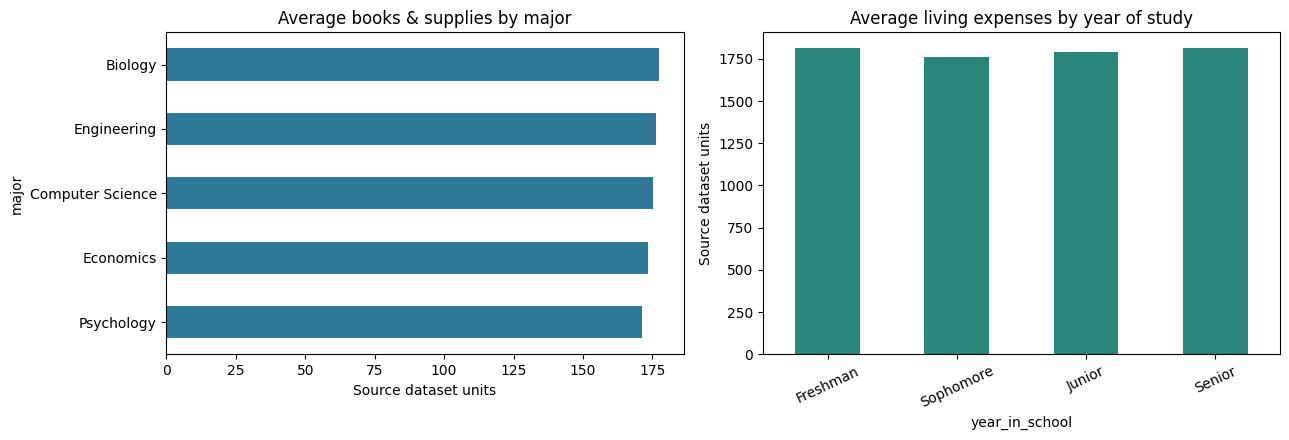

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
major_summary["mean_books_supplies"].sort_values().plot(kind="barh", ax=axes[0], color="#2f7898")
axes[0].set_title("Average books & supplies by major")
axes[0].set_xlabel("Source dataset units")

(year_summary["mean_living_expenses"]).plot(kind="bar", ax=axes[1], color="#288778")
axes[1].set_title("Average living expenses by year of study")
axes[1].set_ylabel("Source dataset units")
axes[1].tick_params(axis="x", rotation=25)
plt.tight_layout()
plt.show()

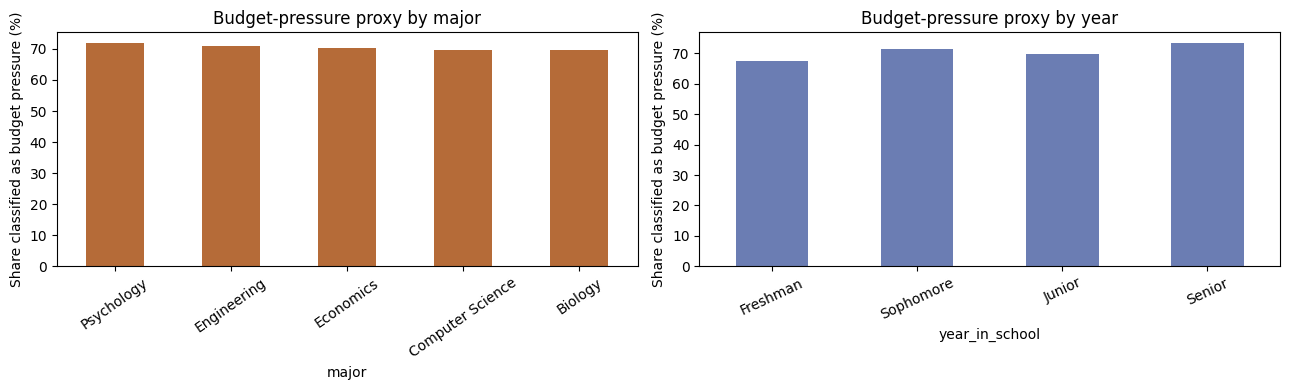

In [9]:
risk_by_major = (df.groupby("major")["budget_risk"].mean().sort_values(ascending=False) * 100)
risk_by_year = (df.groupby("year_in_school")["budget_risk"].mean().reindex(year_order) * 100)
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
risk_by_major.plot(kind="bar", ax=axes[0], color="#b56b38")
axes[0].set_title("Budget-pressure proxy by major")
axes[0].set_ylabel("Share classified as budget pressure (%)")
axes[0].tick_params(axis="x", rotation=35)
risk_by_year.plot(kind="bar", ax=axes[1], color="#6b7db3")
axes[1].set_title("Budget-pressure proxy by year")
axes[1].set_ylabel("Share classified as budget pressure (%)")
axes[1].tick_params(axis="x", rotation=25)
plt.tight_layout()
plt.show()

### Interpreting the course/year analysis

The plots show what the *available dataset* records; they do not establish that first-year students always spend more or that a particular programme always has higher academic-material costs. If the differences are small or inconsistent, that is a valid finding: the current dataset may not contain sufficient course- and year-specific detail. A larger local dataset with Strathmore programme names and finer categories (for example textbooks, studio materials, printing, software and equipment) would be needed to test those examples properly.


## 6. Model inputs and leakage control

The final application asks the student for:
1. Monthly income (source dataset amount).
2. Financial aid (source dataset amount).
3. Course/major (only categories represented in the training data).
4. Year of study.

The following columns are **not** model inputs: age, gender, preferred payment method, actual expense categories, total living expenses, available-funds proxy and target label. These fields are used only to create the training label and to analyse the dataset.


In [10]:
USER_INPUT_FEATURES = ["monthly_income", "financial_aid", "major", "year_in_school"]
NUMERIC_FEATURES = ["monthly_income", "financial_aid"]
CATEGORICAL_FEATURES = ["major", "year_in_school", "study_profile"]
FEATURE_COLUMNS = NUMERIC_FEATURES + CATEGORICAL_FEATURES
TARGET_COLUMN = "budget_risk"

X = df[FEATURE_COLUMNS].copy()
y = df[TARGET_COLUMN].copy()

print("End-user input columns:", USER_INPUT_FEATURES)
print("Derived input column:", "study_profile = major + ' | ' + year_in_school")
print("Model input columns:", FEATURE_COLUMNS)
print("Target:", TARGET_COLUMN)
print("Expense fields excluded from X:", expense_columns)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=RANDOM_STATE
)
print("Training rows:", len(X_train), "| Test rows:", len(X_test))
print("Training budget-pressure rate:", round(y_train.mean(), 3))
print("Test budget-pressure rate:", round(y_test.mean(), 3))


End-user input columns: ['monthly_income', 'financial_aid', 'major', 'year_in_school']
Derived input column: study_profile = major + ' | ' + year_in_school
Model input columns: ['monthly_income', 'financial_aid', 'major', 'year_in_school', 'study_profile']
Target: budget_risk
Expense fields excluded from X: ['housing', 'food', 'transportation', 'books_supplies', 'entertainment', 'personal_care', 'technology', 'health_wellness', 'miscellaneous']
Training rows: 799 | Test rows: 200
Training budget-pressure rate: 0.705
Test budget-pressure rate: 0.705


## 7. Preprocessing and the base Logistic Regression model

- **Missing-value handling:** numeric inputs use the median; categorical inputs use the most common value.
- **Scaling:** numerical inputs are standardised so income variables are on comparable scales.
- **One-hot encoding:** course and year are converted into numeric indicator columns.
- **Logistic Regression:** estimates the probability of the positive class using a logistic (sigmoid) function. The default L2 regularisation helps control overly large coefficients.

All preprocessing is kept inside a scikit-learn `Pipeline`. This ensures that imputers, scalers and encoders are fitted on training folds only, reducing data leakage during cross-validation.


In [11]:
numeric_preprocessor = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_preprocessor = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer(transformers=[
    ("numeric", numeric_preprocessor, NUMERIC_FEATURES),
    ("categorical", categorical_preprocessor, CATEGORICAL_FEATURES)
])

base_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(
        C=1.0, solver="lbfgs", max_iter=3000,
        random_state=RANDOM_STATE
    ))
])

base_model

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('numeric',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  ['monthly_income',
                                                   'financial_aid']),
                                                 ('categorical',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='most_frequent')),
                                                                  ('onehot',
                                                                   OneHotEncoder(handle_unknown='ignore'))]),
                                                  ['major', 'year_in_school',
                                                   'study_profile'])])),
                ('classifier',
                 LogisticRegression(max_iter=3000, random_state=42))])

## 8. Test whether course and year add value

This is a direct response to the lecturer's feedback. We compare two models using the same training folds:
- **Financial-only model:** monthly income and financial aid.
- **Student-context model:** monthly income, financial aid, course/major, year of study, and the derived course-by-year profile.

If the student-context model performs better, course/year provide useful predictive signal in this dataset. If it does not, report that honestly: the current sample may not contain enough course/year-specific information. The model must not pretend to know course-specific costs that the dataset does not record.


In [12]:
from sklearn.metrics import make_scorer

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
scoring = {
    "accuracy": "accuracy",
    "precision": make_scorer(precision_score, zero_division=0),
    "recall": make_scorer(recall_score, zero_division=0),
    "f1": make_scorer(f1_score, zero_division=0),
    "roc_auc": "roc_auc"
}

def make_logistic_pipeline(num_features, cat_features):
    num_pipe = Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler())
    ])
    cat_pipe = Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("onehot", OneHotEncoder(handle_unknown="ignore"))
    ])
    transformers = []
    if len(num_features) > 0:
        transformers.append(("numeric", num_pipe, num_features))
    if len(cat_features) > 0:
        transformers.append(("categorical", cat_pipe, cat_features))
    prep = ColumnTransformer(transformers=transformers)
    return Pipeline([
        ("preprocessor", prep),
        ("classifier", LogisticRegression(C=1.0, max_iter=3000,
                                           solver="lbfgs", random_state=RANDOM_STATE))
    ])

financial_only_model = make_logistic_pipeline(
    ["monthly_income", "financial_aid"], []
)
student_context_model = make_logistic_pipeline(
    NUMERIC_FEATURES, CATEGORICAL_FEATURES
)
models_for_comparison = {
    "Financial-only Logistic Regression": (financial_only_model, X_train[["monthly_income", "financial_aid"]]),
    "Student-context Logistic Regression": (student_context_model, X_train),
    "Majority-class baseline": (DummyClassifier(strategy="most_frequent"), X_train[["monthly_income", "financial_aid"]])
}

comparison_rows = []
for name, (estimator, X_cv) in models_for_comparison.items():
    result = cross_validate(estimator, X_cv, y_train, cv=cv, scoring=scoring, n_jobs=-1)
    comparison_rows.append({
        "Model": name,
        "Accuracy (mean)": result["test_accuracy"].mean(),
        "Precision (mean)": result["test_precision"].mean(),
        "Recall (mean)": result["test_recall"].mean(),
        "F1 (mean)": result["test_f1"].mean(),
        "ROC-AUC (mean)": result["test_roc_auc"].mean()
    })
comparison_table = pd.DataFrame(comparison_rows).sort_values("ROC-AUC (mean)", ascending=False)
display(comparison_table.round(3))


,Model,Accuracy (mean),Precision (mean),Recall (mean),F1 (mean),ROC-AUC (mean)
0,Financial-only Logistic Regression,0.871,0.904,0.915,0.909,0.935
1,Student-context Logistic Regression,0.860,0.894,0.909,0.901,0.928
2,Majority-class baseline,0.705,0.705,1.000,0.827,0.500


## 9. Hyperparameter tuning for the final model

`C` controls the strength of Logistic Regression regularisation. The estimator uses L2 regularisation by default. Smaller values apply stronger regularisation; larger values allow the fitted coefficients to move more freely. We select `C` using cross-validation on the training set only.


In [13]:
param_grid = {"classifier__C": [0.01, 0.1, 1.0, 10.0, 100.0]}
grid_search = GridSearchCV(
    estimator=clone(base_model),
    param_grid=param_grid,
    scoring="roc_auc",
    cv=cv,
    n_jobs=-1,
    refit=True
)
grid_search.fit(X_train, y_train)
final_model = grid_search.best_estimator_

print("Best parameters:", grid_search.best_params_)
print("Best training CV ROC-AUC:", round(grid_search.best_score_, 4))

Best parameters: {'classifier__C': 0.01}
Best training CV ROC-AUC: 0.9335


## 10. Final evaluation on unseen test data

The test set is held back from model fitting and hyperparameter selection. The metrics mean:
- **Accuracy:** proportion of all predictions that are correct.
- **Precision:** among students flagged as at risk, how many were actually labelled at risk.
- **Recall:** among actual at-risk records, how many the model detected.
- **F1:** balance between precision and recall.
- **ROC-AUC:** how well the model ranks at-risk records above within-funds records across decision thresholds.


,Test score
Accuracy,0.840
Precision,0.830
Recall,0.972
F1-score,0.895
ROC-AUC,0.947


                       precision    recall  f1-score   support

Within reported funds       0.89      0.53      0.66        59
      Budget pressure       0.83      0.97      0.90       141

             accuracy                           0.84       200
            macro avg       0.86      0.75      0.78       200
         weighted avg       0.85      0.84      0.83       200



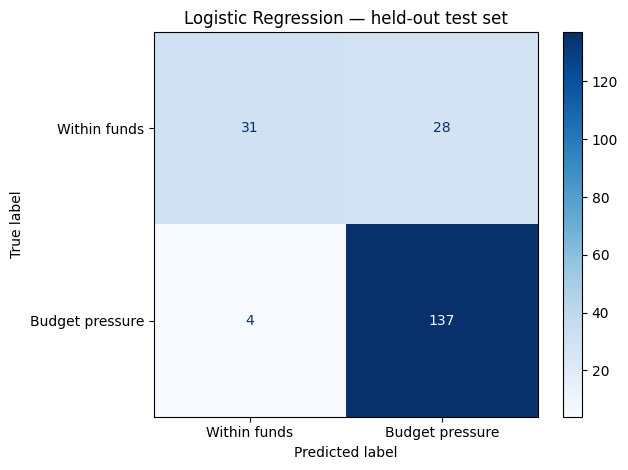

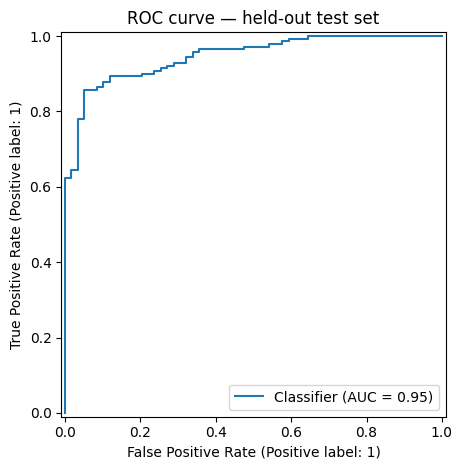

In [14]:
y_pred = final_model.predict(X_test)
y_prob = final_model.predict_proba(X_test)[:, 1]

test_metrics = {
    "Accuracy": accuracy_score(y_test, y_pred),
    "Precision": precision_score(y_test, y_pred, zero_division=0),
    "Recall": recall_score(y_test, y_pred, zero_division=0),
    "F1-score": f1_score(y_test, y_pred, zero_division=0),
    "ROC-AUC": roc_auc_score(y_test, y_prob)
}
metrics_table = pd.DataFrame.from_dict(test_metrics, orient="index", columns=["Test score"])
display(metrics_table.round(3))
print(classification_report(y_test, y_pred,
                            target_names=["Within reported funds", "Budget pressure"],
                            zero_division=0))

ConfusionMatrixDisplay.from_predictions(
    y_test, y_pred,
    display_labels=["Within funds", "Budget pressure"],
    cmap="Blues", values_format="d"
)
plt.title("Logistic Regression — held-out test set")
plt.tight_layout()
plt.show()

RocCurveDisplay.from_predictions(y_test, y_prob)
plt.title("ROC curve — held-out test set")
plt.tight_layout()
plt.show()

## 11. Feature influence and explainable output

Logistic Regression calculates a score called **log-odds** and converts it into a probability using the sigmoid function. Each transformed feature has a coefficient. A positive contribution moves the estimate towards budget pressure; a negative contribution moves it away.

The local explanation reports the intercept (the model's starting score) and the largest feature contributions. Their sum reconstructs the model's log-odds for this profile. This explains how the model used the provided fields; it is **not** a causal explanation and does not prove that a course or year causes a student to spend more.


,input_feature,mean_auc_decrease_when_shuffled,std
0,monthly_income,0.2344,0.0205
1,financial_aid,0.2142,0.0220
2,major,0.0002,0.0006
4,study_profile,-0.0000,0.0006
3,year_in_school,-0.0012,0.0009


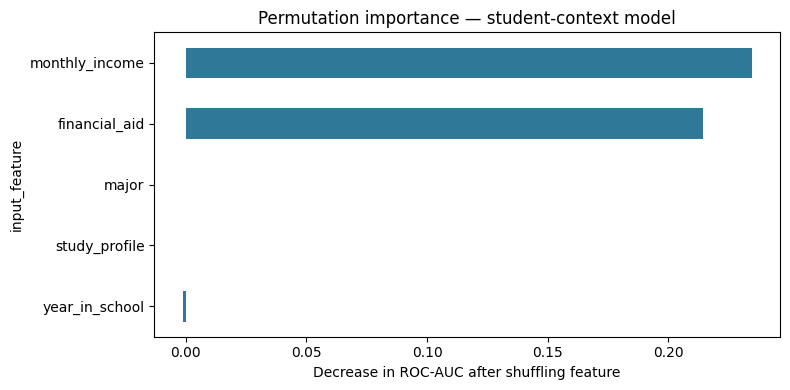

In [15]:
# Global permutation importance at the original input-column level.
perm = permutation_importance(
    final_model, X_test, y_test, n_repeats=10,
    random_state=RANDOM_STATE, scoring="roc_auc", n_jobs=-1
)
importance = pd.DataFrame({
    "input_feature": FEATURE_COLUMNS,
    "mean_auc_decrease_when_shuffled": perm.importances_mean,
    "std": perm.importances_std
}).sort_values("mean_auc_decrease_when_shuffled", ascending=False)
display(importance.round(4))

importance.sort_values("mean_auc_decrease_when_shuffled").plot(
    x="input_feature", y="mean_auc_decrease_when_shuffled", kind="barh",
    legend=False, figsize=(8, 4), color="#2f7898"
)
plt.xlabel("Decrease in ROC-AUC after shuffling feature")
plt.title("Permutation importance — student-context model")
plt.tight_layout()
plt.show()

## 12. End-user prediction function with input validation and explanation

The demo accepts monthly income, financial aid, course/major and year of study. It rejects negative or non-numeric amounts, missing values, unsupported majors (such as Law or Architecture) and unsupported years. New programmes must not be silently mapped to an existing major; representative local data is needed before adding them.


In [16]:
ALLOWED_MAJORS = sorted(df["major"].dropna().unique().tolist())
ALLOWED_YEARS = ["Freshman", "Sophomore", "Junior", "Senior"]


def validate_student_input(profile):
    required = USER_INPUT_FEATURES
    missing = [col for col in required if col not in profile or profile[col] is None]
    if missing:
        raise ValueError(f"Missing required input(s): {missing}")

    try:
        income = float(profile["monthly_income"])
        aid = float(profile["financial_aid"])
    except (TypeError, ValueError):
        raise ValueError("Monthly income and financial aid must be numeric values.")

    if not np.isfinite(income) or not np.isfinite(aid):
        raise ValueError("Financial inputs must be finite numbers.")
    if income < 0 or aid < 0:
        raise ValueError("Monthly income and financial aid cannot be negative.")

    major = str(profile["major"]).strip()
    year = str(profile["year_in_school"]).strip()
    if major not in ALLOWED_MAJORS:
        raise ValueError(
            "This course/major is not represented in the training dataset. "
            f"Supported categories are: {ALLOWED_MAJORS}. Collect representative data and retrain before supporting a new programme."
        )
    if year not in ALLOWED_YEARS:
        raise ValueError(f"Year of study must be one of: {ALLOWED_YEARS}")

    return {
        "monthly_income": income,
        "financial_aid": aid,
        "major": major,
        "year_in_school": year,
        "study_profile": f"{major} | {year}"
    }


def explain_prediction(model, input_frame, top_n=6):
    prep = model.named_steps["preprocessor"]
    clf = model.named_steps["classifier"]
    transformed = prep.transform(input_frame)
    if hasattr(transformed, "toarray"):
        transformed = transformed.toarray()
    feature_names = prep.get_feature_names_out()
    contributions = transformed[0] * clf.coef_[0]
    intercept = float(clf.intercept_[0])
    log_odds = intercept + float(np.sum(contributions))
    reconstructed_probability = 1.0 / (1.0 + np.exp(-log_odds))

    exp = pd.DataFrame({
        "model_feature": feature_names,
        "log_odds_contribution": contributions
    })
    exp = exp[exp["log_odds_contribution"].abs() > 1e-8].copy()
    exp["direction"] = np.where(
        exp["log_odds_contribution"] > 0,
        "Pushes towards budget pressure",
        "Pushes away from budget pressure"
    )
    exp = exp.sort_values("log_odds_contribution", key=lambda s: s.abs(), ascending=False).head(top_n)
    summary = {
        "base_log_odds_intercept": intercept,
        "sum_of_feature_contributions": float(np.sum(contributions)),
        "reconstructed_log_odds": log_odds,
        "reconstructed_probability": float(reconstructed_probability)
    }
    return exp, summary


def predict_budget_risk(profile, model=final_model):
    valid = validate_student_input(profile)
    input_frame = pd.DataFrame([valid], columns=FEATURE_COLUMNS)
    probability = float(model.predict_proba(input_frame)[0, 1])
    predicted_class = int(probability >= 0.50)
    explanation, xai_summary = explain_prediction(model, input_frame, top_n=6)
    return {
        "predicted_class": predicted_class,
        "label": label_map[predicted_class],
        "budget_pressure_probability": probability,
        "input_used": {k: valid[k] for k in USER_INPUT_FEATURES},
        "study_profile": valid["study_profile"],
        "explanation": explanation,
        "xai_summary": xai_summary
    }

print("Supported majors:", ALLOWED_MAJORS)
print("Supported years:", ALLOWED_YEARS)


Supported majors: ['Biology', 'Computer Science', 'Economics', 'Engineering', 'Psychology']
Supported years: ['Freshman', 'Sophomore', 'Junior', 'Senior']


## 13. Live end-user demonstration: vary the student profile

The following examples imitate the information a student would enter in SmartSpend. The predicted probabilities are generated by the fitted model when the notebook is run; they are not hard-coded.

The first comparison changes financial resources. The second keeps the money inputs fixed and changes course/year to test whether the model uses student context. If the second result changes only slightly, do not force a claim: it may indicate that the training dataset does not contain a strong course/year signal.


In [17]:
# Scenario A: an early-year student with relatively limited reported resources.
scenario_a = {
    "monthly_income": 600,
    "financial_aid": 100,
    "major": ALLOWED_MAJORS[0],
    "year_in_school": "Freshman"
}

# Scenario B: same course/year, but higher reported financial resources.
scenario_b = {
    **scenario_a,
    "monthly_income": 1400,
    "financial_aid": 500
}

# Scenario C: same financial resources as A, but a different supported course/year profile.
scenario_c = {
    **scenario_a,
    "major": ALLOWED_MAJORS[-1],
    "year_in_school": "Senior"
}

for label, scenario in [("A — lower resources", scenario_a),
                        ("B — higher resources", scenario_b),
                        ("C — changed course and year", scenario_c)]:
    result = predict_budget_risk(scenario)
    print("\n", label)
    print("Inputs:", result["input_used"])
    print("Derived student profile:", result["study_profile"])
    print("Prediction:", result["label"])
    print("Predicted budget-pressure probability:", f"{result['budget_pressure_probability']:.1%}")
    print("XAI summary:", result["xai_summary"])
    display(result["explanation"])



 A — lower resources
Inputs: {'monthly_income': 600.0, 'financial_aid': 100.0, 'major': 'Biology', 'year_in_school': 'Freshman'}
Derived student profile: Biology | Freshman
Prediction: Budget pressure
Predicted budget-pressure probability: 95.8%
XAI summary: {'base_log_odds_intercept': 1.0698393144712632, 'sum_of_feature_contributions': 2.0569212609949106, 'reconstructed_log_odds': 3.126760575466174, 'reconstructed_probability': 0.9579831948674736}


,model_feature,log_odds_contribution,direction
0,numeric__monthly_income,1.070393,Pushes towards budget pressure
1,numeric__financial_aid,0.996774,Pushes towards budget pressure
7,categorical__year_in_school_Freshman,-0.020498,Pushes away from budget pressure
11,categorical__study_profile_Biology | Freshman,0.014342,Pushes towards budget pressure
2,categorical__major_Biology,-0.004089,Pushes away from budget pressure



 B — higher resources
Inputs: {'monthly_income': 1400.0, 'financial_aid': 500.0, 'major': 'Biology', 'year_in_school': 'Freshman'}
Derived student profile: Biology | Freshman
Prediction: Budget pressure
Predicted budget-pressure probability: 52.7%
XAI summary: {'base_log_odds_intercept': 1.0698393144712632, 'sum_of_feature_contributions': -0.9609829299049781, 'reconstructed_log_odds': 0.1088563845662851, 'reconstructed_probability': 0.5271872546796367}


,model_feature,log_odds_contribution,direction
0,numeric__monthly_income,-0.953422,Pushes away from budget pressure
7,categorical__year_in_school_Freshman,-0.020498,Pushes away from budget pressure
11,categorical__study_profile_Biology | Freshman,0.014342,Pushes towards budget pressure
2,categorical__major_Biology,-0.004089,Pushes away from budget pressure
1,numeric__financial_aid,0.002684,Pushes towards budget pressure



 C — changed course and year
Inputs: {'monthly_income': 600.0, 'financial_aid': 100.0, 'major': 'Psychology', 'year_in_school': 'Senior'}
Derived student profile: Psychology | Senior
Prediction: Budget pressure
Predicted budget-pressure probability: 96.2%
XAI summary: {'base_log_odds_intercept': 1.0698393144712632, 'sum_of_feature_contributions': 2.1562927247002697, 'reconstructed_log_odds': 3.226132039171533, 'reconstructed_probability': 0.9618059157755133}


,model_feature,log_odds_contribution,direction
0,numeric__monthly_income,1.070393,Pushes towards budget pressure
1,numeric__financial_aid,0.996774,Pushes towards budget pressure
9,categorical__year_in_school_Senior,0.046008,Pushes towards budget pressure
29,categorical__study_profile_Psychology | Senior,0.029637,Pushes towards budget pressure
6,categorical__major_Psychology,0.013481,Pushes towards budget pressure


## 14. Invalid-input testing

Invalid inputs must be rejected with a clear message rather than producing a misleading prediction. The notebook tests negative money values, a course not represented in the data (for example Law), an invalid year and a missing field.


In [18]:
invalid_cases = {
    "Negative income": {**scenario_a, "monthly_income": -200},
    "Unsupported major (Law)": {**scenario_a, "major": "Law"},
    "Unsupported major (Architecture)": {**scenario_a, "major": "Architecture"},
    "Unsupported year": {**scenario_a, "year_in_school": "Graduate"},
    "Missing financial aid": {k: v for k, v in scenario_a.items() if k != "financial_aid"},
    "Non-numeric income": {**scenario_a, "monthly_income": "unknown"}
}

for test_name, bad_input in invalid_cases.items():
    try:
        predict_budget_risk(bad_input)
        print(f"{test_name}: ERROR — invalid input was not rejected")
    except ValueError as exc:
        print(f"{test_name}: correctly rejected → {exc}")


Negative income: correctly rejected → Monthly income and financial aid cannot be negative.
Unsupported major (Law): correctly rejected → This course/major is not represented in the training dataset. Supported categories are: ['Biology', 'Computer Science', 'Economics', 'Engineering', 'Psychology']. Collect representative data and retrain before supporting a new programme.
Unsupported major (Architecture): correctly rejected → This course/major is not represented in the training dataset. Supported categories are: ['Biology', 'Computer Science', 'Economics', 'Engineering', 'Psychology']. Collect representative data and retrain before supporting a new programme.
Unsupported year: correctly rejected → Year of study must be one of: ['Freshman', 'Sophomore', 'Junior', 'Senior']
Missing financial aid: correctly rejected → Missing required input(s): ['financial_aid']
Non-numeric income: correctly rejected → Monthly income and financial aid must be numeric values.


## 15. Export the final model for the application

The final fitted pipeline includes preprocessing and Logistic Regression in one object. The application loads this file and passes a validated student profile to it. The metadata file records the supported categories and target definition so that the app can validate inputs consistently.


In [19]:
MODEL_FILE = "smartspend_budget_risk_logreg.joblib"
METADATA_FILE = "smartspend_model_metadata.json"

joblib.dump(final_model, MODEL_FILE)
metadata = {
    "project": "SmartSpend",
    "model": "Logistic Regression (L2 regularisation)",
    "target": TARGET_COLUMN,
    "target_definition": "1 when total non-tuition living expenses exceed monthly_income + financial_aid; otherwise 0",
    "positive_class": "Budget pressure (dataset proxy)",
    "negative_class": "Within reported funds",
    "decision_threshold": 0.50,
    "input_features": FEATURE_COLUMNS,
    "user_input_features": USER_INPUT_FEATURES,
    "numeric_features": NUMERIC_FEATURES,
    "categorical_features": CATEGORICAL_FEATURES,
    "allowed_majors": ALLOWED_MAJORS,
    "allowed_years": ALLOWED_YEARS,
    "dataset_source": "https://www.kaggle.com/datasets/sumanthnimmagadda/student-spending-dataset",
    "source_units": "USD-style values as described by the source dataset; not Kenyan Shillings",
    "limitations": [
        "Illustrative student dataset; not a representative sample of Kenyan or Strathmore students.",
        "Only the major categories in the source dataset are supported.",
        "Course-specific costs such as Law textbooks and Architecture studio materials are not separately represented.",
        "The time period for financial_aid is not clearly documented; the target is a budget-pressure proxy, not a verified monthly deficit.",
        "Predictions are estimates and not financial advice."
    ],
    "test_metrics": {k: float(v) for k, v in test_metrics.items()},
    "best_parameters": grid_search.best_params_
}
with open(METADATA_FILE, "w", encoding="utf-8") as f:
    json.dump(metadata, f, indent=2)

print("Saved:", MODEL_FILE)
print("Saved:", METADATA_FILE)
print("Final model test metrics:")
display(metrics_table.round(3))

Saved: smartspend_budget_risk_logreg.joblib
Saved: smartspend_model_metadata.json
Final model test metrics:


,Test score
Accuracy,0.840
Precision,0.830
Recall,0.972
F1-score,0.895
ROC-AUC,0.947


In [20]:
# Reload the saved model to confirm the exported artifact can be used by the app.
reloaded_model = joblib.load(MODEL_FILE)
reloaded_result = predict_budget_risk(scenario_a, model=reloaded_model)
print("Reloaded artifact prediction:", reloaded_result["label"])
print("Probability:", round(reloaded_result["budget_pressure_probability"], 4))

# In Google Colab, uncomment these lines to download the artifacts to your computer:
# from google.colab import files
# files.download(MODEL_FILE)
# files.download(METADATA_FILE)

Reloaded artifact prediction: Budget pressure
Probability: 0.958


## 16. What this model can and cannot claim

### It can demonstrate
- A trained supervised-learning classifier using student-related records.
- Inputs that include course/major and year of study.
- A probability estimate and binary budget-pressure label.
- A transparent, reproducible preprocessing and training workflow.
- Input validation and an explanation of which fitted features pushed a prediction up or down.

### It cannot yet claim
- That it represents all Kenyan university students or Strathmore students.
- That Law, Architecture or other unsupported programme costs have been learned.
- That first-year students always spend more than final-year students.
- That a prediction is a guaranteed financial outcome or causal explanation.
- That questionnaire responses are training labels. The questionnaire is primary evidence for the problem and app requirements, not a substitute for a sufficiently large labelled training dataset.

### Next data improvement
Collect anonymised local records with consent and relevant fields: institution/programme, year of study, monthly income sources, aid/allowance frequency, category-level monthly expenses, academic materials/equipment costs, and optional housing/commute context. Ensure the data period and currency are consistent. Add Law/Architecture only when representative examples are collected.


## 17. References

Nimmagadda, S. (n.d.). *Student spending habits dataset* [Data set]. Kaggle. https://www.kaggle.com/datasets/sumanthnimmagadda/student-spending-dataset

scikit-learn developers. (n.d.). *LogisticRegression*. scikit-learn documentation. https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.LogisticRegression.html

scikit-learn developers. (n.d.). *Pipelines and composite estimators*. scikit-learn documentation. https://scikit-learn.org/stable/modules/compose.html

scikit-learn developers. (n.d.). *ColumnTransformer*. scikit-learn documentation. https://scikit-learn.org/stable/modules/generated/sklearn.compose.ColumnTransformer.html

**Dataset note:** The Kaggle page is the source of the dataset. A public CSV mirror may be used only as a download fallback; verify the current dataset licence and redistribution conditions before committing the CSV to a public repository.
